   # UTS Graf Sains Data
   Nama: Dimas Reza Perdana · NIM: 23031554130

In [2]:
import pandas as pd
import neo4j
print("pandas", pd.__version__, "| neo4j", neo4j.__version__)

pandas 3.0.6 | neo4j 6.4.1


In [3]:
df = pd.read_csv("data/events.csv")
print("Jumlah baris:", len(df))
df.head()

Jumlah baris: 2756101


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB


In [5]:
print(df["event"].value_counts())
print("Visitor unik:", df["visitorid"].nunique())
print("Item unik   :", df["itemid"].nunique())

event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64
Visitor unik: 1407580
Item unik   : 235061


In [6]:
df["waktu"] = pd.to_datetime(df["timestamp"], unit="ms", utc=True)
print("Data mulai  :", df["waktu"].min())
print("Data selesai:", df["waktu"].max())

Data mulai  : 2015-05-03 03:00:04.384000+00:00
Data selesai: 2015-09-18 02:59:47.788000+00:00


## 2.1 No. 1 — Menentukan periode

In [9]:
P1 = ("2015-05-23", "2015-07-23")   # fold training
P2 = ("2015-08-01", "2015-08-16")   # fold testing

def ke_ms(tanggal, akhir=False):
    t = pd.Timestamp(tanggal, tz="UTC")
    if akhir:
        t = t + pd.Timedelta(days=1)
    return int(t.timestamp() * 1000)

awal_P1, akhir_P1 = ke_ms(P1[0]), ke_ms(P1[1], akhir=True)
awal_P2, akhir_P2 = ke_ms(P2[0]), ke_ms(P2[1], akhir=True)
print("P1:", awal_P1, "s.d.", akhir_P1)
print("P2:", awal_P2, "s.d.", akhir_P2)

P1: 1432339200000 s.d. 1437696000000
P2: 1438387200000 s.d. 1439769600000


In [10]:
mask_P1 = (df["timestamp"] >= awal_P1) & (df["timestamp"] < akhir_P1)
mask_P2 = (df["timestamp"] >= awal_P2) & (df["timestamp"] < akhir_P2)
print("Baris P1:", mask_P1.sum())
print("Baris P2:", mask_P2.sum())
print(f"Porsi P1+P2 dari seluruh data: {(mask_P1 | mask_P2).mean():.1%}")

Baris P1: 1287630
Baris P2: 280001
Porsi P1+P2 dari seluruh data: 56.9%


## 2.1 No. 2 — Filter timestamp dan simpan ke CSV

In [11]:
import numpy as np

df["fold"] = np.select([mask_P1, mask_P2], ["P1", "P2"], default="-")
df_f = df[df["fold"] != "-"].copy()
print("Baris setelah filter:", len(df_f))
df_f["fold"].value_counts()

Baris setelah filter: 1567631


fold
P1    1287630
P2     280001
Name: count, dtype: int64

In [12]:
pd.crosstab(df_f["fold"], df_f["event"], margins=True)

event,addtocart,transaction,view,All
fold,,,,
P1,32054,10644,1244932,1287630
P2,7428,2169,270404,280001
All,39482,12813,1515336,1567631


In [13]:
df_f.groupby("fold").agg(visitor_unik=("visitorid", "nunique"),
                         item_unik=("itemid", "nunique"))

,visitor_unik,item_unik
fold,,
P1,664865,169828
P2,162337,78365


In [14]:
item_per_visitor = df_f.groupby(["fold", "visitorid"])["itemid"].nunique()
item_per_visitor.describe(percentiles=[.5, .9, .99, .999, .9999])

count     827202.000000
mean           1.480603
std            5.695162
min            1.000000
50%            1.000000
90%            2.000000
99%            7.000000
99.9%         25.000000
99.99%       174.279900
max         2104.000000
Name: itemid, dtype: float64

In [15]:
item_per_visitor.sort_values(ascending=False).head(10)

fold  visitorid
P1    1150086      2104
      371606       1399
      684514       1187
      530559       1076
      836635       1029
P2    1150086       910
P1    1297062       874
      765630        820
      757355        726
      895999        725
Name: itemid, dtype: int64

In [16]:
sisi = item_per_visitor * (item_per_visitor - 1) // 2      # C(d,2) per visitor
total_sisi = sisi.sum()
print(f"Total batas atas sisi proyeksi item: {total_sisi:,}")

for batas in [100, 200, 500]:
    bot = item_per_visitor > batas
    print(f"> {batas:>3} item: {bot.sum():>3} visitor "
          f"| menyumbang {sisi[bot].sum():,} sisi ({sisi[bot].sum() / total_sisi:.0%} dari total)")

Total batas atas sisi proyeksi item: 13,709,392
> 100 item: 144 visitor | menyumbang 12,124,653 sisi (88% dari total)
> 200 item:  78 visitor | menyumbang 11,462,262 sisi (84% dari total)
> 500 item:  18 visitor | menyumbang 8,176,752 sisi (60% dari total)


In [17]:
BATAS_BOT = 200
bot = item_per_visitor[item_per_visitor > BATAS_BOT]
pasangan_bot = set(bot.index)          # isi: {("P1", 1150086), ("P2", 1150086), ...}

dibuang = pd.Series([(f, v) in pasangan_bot for f, v in zip(df_f["fold"], df_f["visitorid"])],
                    index=df_f.index)
print(f"Visitor bot: {len(bot)} | baris dibuang: {dibuang.sum():,} ({dibuang.mean():.2%})")
df_f = df_f[~dibuang].copy()
print("Baris tersisa:", len(df_f))

Visitor bot: 78 | baris dibuang: 56,292 (3.59%)
Baris tersisa: 1511339


In [18]:
df_f["transactionid"] = df_f["transactionid"].map(lambda x: "" if pd.isna(x) else str(int(x)))

kolom = ["timestamp", "visitorid", "event", "itemid", "transactionid", "fold"]
df_f.loc[df_f["fold"] == "P1", kolom].to_csv("data/events_P1.csv", index=False)
df_f.loc[df_f["fold"] == "P2", kolom].to_csv("data/events_P2.csv", index=False)
print("Tersimpan: data/events_P1.csv dan data/events_P2.csv")

Tersimpan: data/events_P1.csv dan data/events_P2.csv


### Penjelasan No. 1 — Menentukan periode
Data RetailRocket mencakup 3 Mei 2015 sampai 18 September 2015 (UTC), sehingga periode yang ditetapkan
dipakai pada tahun 2015: fold training **P1 = 23 Mei – 23 Juli 2015** dan fold testing **P2 = 1 – 16 Agustus 2015**.
P1 dibuat lebih dulu dan tidak tumpang tindih dengan P2 agar model hanya belajar dari masa lalu lalu diuji
pada masa depan, sehingga tidak terjadi kebocoran data (*data leakage*). Rentang 24–31 Juli sengaja tidak
dipakai sebagai jeda antara data latih dan data uji.

### Penjelasan No. 2 — Filter timestamp dan penyimpanan CSV
Kolom `timestamp` berformat Unix epoch dalam milidetik, sehingga batas periode juga diubah ke milidetik,
dengan batas akhir ditambah 1 hari agar tanggal terakhir ikut terhitung penuh (rentang [awal, akhir)).
Hasil filter: P1 berisi 1.287.630 baris dan P2 berisi 280.001 baris, atau 56,9% dari seluruh data.
Visitor dengan lebih dari 200 item unik dalam satu fold dianggap bot, karena batas ini berada di atas
persentil 99,99% (174 item). Pembersihan ini hanya membuang 78 visitor (dihitung per fold) atau 56.292 baris (3,59%),
padahal mereka menyumbang 84% sisi pada proyeksi item. Data akhir sebanyak 1.511.339 baris disimpan ke
`data/events_P1.csv` dan `data/events_P2.csv`.

## Koneksi ke Neo4j

In [20]:
from neo4j import GraphDatabase, RoutingControl, Result

NEO4J_URI  = "neo4j://127.0.0.1:7687"
NEO4J_AUTH = ("neo4j", "12345678")
NEO4J_DB   = "neo4j"

driver = GraphDatabase.driver(NEO4J_URI, auth=NEO4J_AUTH)
driver.verify_connectivity()
print("Terhubung ke Neo4j!")

Terhubung ke Neo4j!


In [21]:
def cypher(query, write=False, **params):
    """Jalankan query Cypher, hasilnya berupa pandas DataFrame."""
    return driver.execute_query(
        query,
        parameters_=params,
        database_=NEO4J_DB,
        routing_=RoutingControl.WRITE if write else RoutingControl.READ,
        result_transformer_=Result.to_df,
    )

cypher("MATCH (n) RETURN count(n) AS jumlah_simpul")

,jumlah_simpul
0,0


## Impor data ke Neo4j

In [22]:
cypher("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE", write=True)
cypher("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE", write=True)
cypher("SHOW CONSTRAINTS YIELD name, labelsOrTypes, properties")

,name,labelsOrTypes,properties
0,item_id,[Item],[itemId]
1,visitor_id,[Visitor],[visitorId]


In [23]:
IMPOR_CYPHER = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
FOREACH (x IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    CREATE (v)-[:VIEWED {timestamp: row.timestamp, fold: row.fold}]->(i))
FOREACH (x IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, fold: row.fold}]->(i))
FOREACH (x IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, fold: row.fold, transactionId: row.transactionid}]->(i))
"""

def import_batch(tx, batch):
    tx.run(IMPOR_CYPHER, batch=batch).consume()

In [24]:
import math, time
from tqdm import tqdm

BATCH_SIZE = 10_000
t0 = time.perf_counter()
with driver.session(database=NEO4J_DB) as session:
    for fold in ["P1", "P2"]:
        n_baris = (df_f["fold"] == fold).sum()
        chunks = pd.read_csv(f"data/events_{fold}.csv", chunksize=BATCH_SIZE, dtype={"transactionid": str})
        for chunk in tqdm(chunks, total=math.ceil(n_baris / BATCH_SIZE), desc=f"Impor {fold}"):
            chunk["transactionid"] = chunk["transactionid"].fillna("")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
print(f"Impor selesai dalam {time.perf_counter() - t0:.0f} detik")

Impor P2: 100%|██████████| 28/28 [00:27<00:00,  1.01it/s]

Impor selesai dalam 170 detik


## 2.1 No. 3 — Komposisi subgraph

In [25]:
komposisi_simpul = cypher("""
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
""")
komposisi_simpul

,jenis_simpul,jumlah
0,Visitor,817266
1,Item,184033


In [26]:
komposisi_relasi = cypher("""
MATCH ()-[r]->()
RETURN r.fold AS fold, type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY fold, jumlah DESC
""")
komposisi_relasi

,fold,jenis_relasi,jumlah
0,P1,VIEWED,1200458
1,P1,ADDED_TO_CART,28813
2,P1,BOUGHT,8181
3,P2,VIEWED,265072
4,P2,ADDED_TO_CART,6990
5,P2,BOUGHT,1825


In [27]:
komposisi_fold = cypher("""
MATCH (v:Visitor)-[r]->(i:Item)
RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS relasi
ORDER BY fold
""")
komposisi_fold

,fold,visitor,item,relasi
0,P1,664796,167663,1237452
1,P2,162328,77796,273887


In [28]:
print("Total relasi di Neo4j:", komposisi_relasi["jumlah"].sum(), "| baris di df_f:", len(df_f))
print("Visitor unik pandas  :", df_f["visitorid"].nunique())
print("Item unik pandas     :", df_f["itemid"].nunique())

Total relasi di Neo4j: 1511339 | baris di df_f: 1511339
Visitor unik pandas  : 817266
Item unik pandas     : 184033


### Penjelasan No. 3 — Komposisi subgraph
Subgraph hasil impor adalah **graf bipartit berarah** dengan dua jenis simpul: **Visitor** sebanyak 817.266
dan **Item** sebanyak 184.033, yang dihubungkan oleh 1.511.339 relasi berarah dari Visitor ke Item.
Relasi terbagi menjadi tiga tipe sesuai jenis event, yaitu `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`,
dan setiap relasi menyimpan properti `timestamp` dan `fold`. Simpul tidak diberi label fold, sehingga visitor
atau item yang aktif di P1 dan P2 hanya muncul satu kali. Seluruh jumlah ini identik dengan perhitungan pandas,
yang membuktikan proses impor lengkap tanpa duplikasi.

**Cypher yang digunakan** (dijalankan lewat Python API `driver.execute_query`):
- `MATCH (n) RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah` — mengambil semua simpul lalu menghitungnya
  per label. Cypher tidak memakai `GROUP BY`; pengelompokan terjadi otomatis pada kolom non-agregasi (`jenis_simpul`).
- `MATCH ()-[r]->() RETURN r.fold, type(r), count(r)` — menghitung relasi per fold dan per tipe relasi.
- `MATCH (v:Visitor)-[r]->(i:Item) RETURN r.fold, count(DISTINCT v), count(DISTINCT i)` — menghitung visitor dan
  item unik per fold. `DISTINCT` mencegah simpul yang punya banyak relasi terhitung berulang kali.

## 2.1 No. 4 — VSM simpul User

In [29]:
pasangan_P1 = cypher("""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.fold = 'P1'
RETURN v.visitorId AS visitorid, i.itemId AS itemid, count(r) AS n_interaksi
""")
print("Pasangan unik (visitor, item) di P1:", len(pasangan_P1))
pasangan_P1.head()

Pasangan unik (visitor, item) di P1: 969116


,visitorid,itemid,n_interaksi
0,257597,355908,1
1,981382,355908,1
2,62710,355908,1
3,979686,355908,1
4,479732,355908,1


In [30]:
import scipy.sparse as sp

idx_user = pd.Index(np.sort(pasangan_P1["visitorid"].unique()))
idx_item = pd.Index(np.sort(pasangan_P1["itemid"].unique()))
posisi_baris = idx_user.get_indexer(pasangan_P1["visitorid"])
posisi_kolom = idx_item.get_indexer(pasangan_P1["itemid"])

B = sp.csr_matrix((np.ones(len(pasangan_P1)), (posisi_baris, posisi_kolom)),
                  shape=(len(idx_user), len(idx_item)))
print("Shape matriks B (user x item):", B.shape)
print("Jumlah elemen bernilai 1     :", B.nnz)

Shape matriks B (user x item): (664796, 167663)
Jumlah elemen bernilai 1     : 969116


In [31]:
deg_user = np.asarray(B.sum(axis=1)).ravel()   # jumlah item per user
n_user, n_item = B.shape

print(f"Jumlah vektor user  : {n_user:,}")
print(f"Dimensi vektor user : {n_item:,}")
print(f"Densitas            : {B.nnz / (n_user * n_item):.6%}")
print(f"Sparsity            : {1 - B.nnz / (n_user * n_item):.6%}")
print(f"Rata-rata item/user : {deg_user.mean():.2f}")
print(f"Median item/user    : {np.median(deg_user):.0f}")
print(f"Maks item/user      : {deg_user.max():.0f}")
print(f"User dengan 1 item  : {(deg_user == 1).mean():.1%}")
print(f"Memori sparse       : {(B.data.nbytes + B.indices.nbytes + B.indptr.nbytes) / 2**20:.1f} MB")
print(f"Memori jika padat   : {n_user * n_item * 8 / 2**30:,.0f} GB")

Jumlah vektor user  : 664,796
Dimensi vektor user : 167,663
Densitas            : 0.000869%
Sparsity            : 99.999131%
Rata-rata item/user : 1.46
Median item/user    : 1
Maks item/user      : 194
User dengan 1 item  : 80.5%
Memori sparse       : 13.6 MB
Memori jika padat   : 830 GB


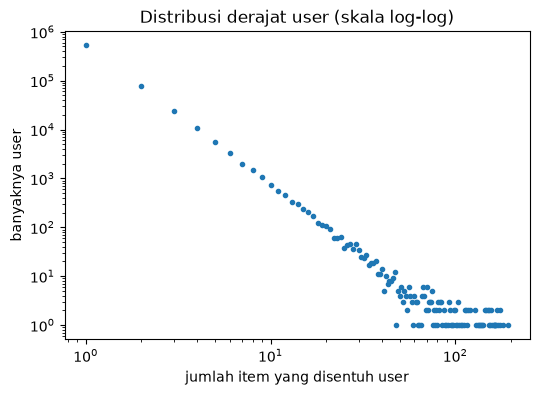

In [32]:
import matplotlib.pyplot as plt

nilai, frek = np.unique(deg_user, return_counts=True)
plt.figure(figsize=(6, 4))
plt.loglog(nilai, frek, "o", ms=3)
plt.xlabel("jumlah item yang disentuh user")
plt.ylabel("banyaknya user")
plt.title("Distribusi derajat user (skala log-log)")
plt.show()

In [34]:
deg_item = np.asarray(B.sum(axis=0)).ravel()       # jumlah user per item
batas_atas_user = int((deg_item * (deg_item - 1) / 2).sum())
maks_sisi_user = n_user * (n_user - 1) // 2
punya_tetangga = np.asarray(B @ (deg_item >= 2).astype(float)).ravel() > 0

print(f"Simpul proyeksi user          : {n_user:,}")
print(f"Sisi maksimum n(n-1)/2        : {maks_sisi_user:,}")
print(f"Batas atas sisi Σ C(d_item,2) : {batas_atas_user:,}")
print(f"Item terpopuler disentuh      : {deg_item.max():,.0f} user")
print(f"User yang punya tetangga      : {punya_tetangga.mean():.1%}")
print(f"Perkiraan memori proyeksi     : {batas_atas_user * 24 / 2**30:,.1f} GB")

Simpul proyeksi user          : 664,796
Sisi maksimum n(n-1)/2        : 220,976,528,410
Batas atas sisi Σ C(d_item,2) : 21,280,204
Item terpopuler disentuh      : 1,621 user
User yang punya tetangga      : 93.2%
Perkiraan memori proyeksi     : 0.5 GB


In [35]:
import networkx as nx
from networkx.algorithms import bipartite

SEED = 23031554130                  # NIM sebagai seed, supaya hasil acaknya bisa direproduksi
rng = np.random.default_rng(SEED)
BT = B.T.tocsr()                    # matriks item x user (dipakai lagi di no. 5)

calon = [u for u in np.flatnonzero((deg_user >= 3) & (deg_user <= 5))
         if 2 <= deg_item[B[u].indices].min() and deg_item[B[u].indices].max() <= 10]
u0 = int(rng.choice(calon))
item_sampel = B[u0].indices

G = nx.Graph()
for i in item_sampel:
    for u in BT[i].indices:
        G.add_edge(f"U{idx_user[u]}", f"I{idx_item[i]}")
user_nodes = [n for n in G if n.startswith("U")]
P_user = bipartite.weighted_projected_graph(G, user_nodes)
print("User pusat:", idx_user[u0], "| item:", len(item_sampel), "| user di sampel:", len(user_nodes))

User pusat: 345557 | item: 4 | user di sampel: 11


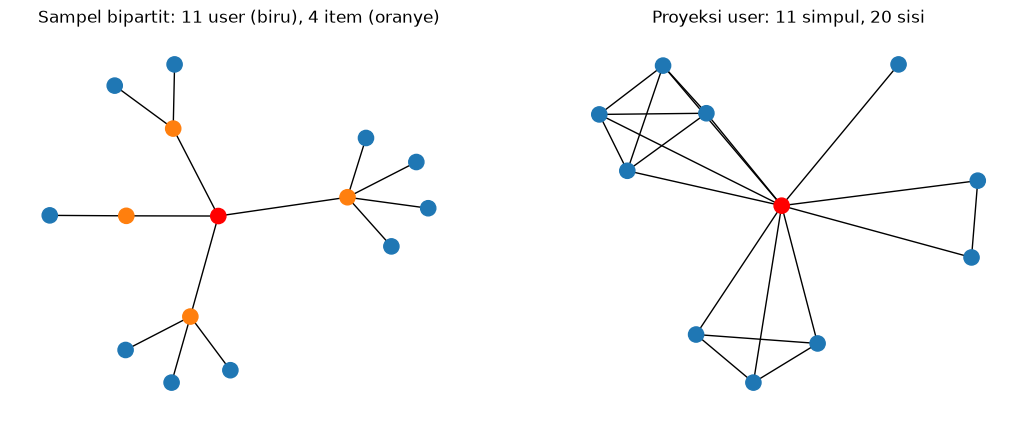

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pusat = f"U{idx_user[u0]}"

pos = nx.spring_layout(G, seed=1)
warna = ["tab:orange" if n.startswith("I") else ("red" if n == pusat else "tab:blue") for n in G]
nx.draw(G, pos, ax=ax[0], node_color=warna, node_size=120)
ax[0].set_title(f"Sampel bipartit: {len(user_nodes)} user (biru), {len(item_sampel)} item (oranye)")

pos2 = nx.spring_layout(P_user, seed=1)
warna2 = ["red" if n == pusat else "tab:blue" for n in P_user]
lebar = [P_user[a][b]["weight"] for a, b in P_user.edges()]
nx.draw(P_user, pos2, ax=ax[1], node_color=warna2, node_size=120, width=lebar)
ax[1].set_title(f"Proyeksi user: {P_user.number_of_nodes()} simpul, {P_user.number_of_edges()} sisi")
plt.show()

## 2.1 No. 5 — VSM simpul Item

In [37]:
print(f"Shape matriks BT (item x user): {BT.shape}")
print(f"Jumlah vektor item  : {n_item:,}")
print(f"Dimensi vektor item : {n_user:,}")
print(f"Densitas            : {BT.nnz / (n_item * n_user):.6%}")
print(f"Rata-rata user/item : {deg_item.mean():.2f}")
print(f"Median user/item    : {np.median(deg_item):.0f}")
print(f"Maks user/item      : {deg_item.max():.0f}")
print(f"Item dengan 1 user  : {(deg_item == 1).mean():.1%}")
print(f"Memori sparse       : {(BT.data.nbytes + BT.indices.nbytes + BT.indptr.nbytes) / 2**20:.1f} MB")

Shape matriks BT (item x user): (167663, 664796)
Jumlah vektor item  : 167,663
Dimensi vektor item : 664,796
Densitas            : 0.000869%
Rata-rata user/item : 5.78
Median user/item    : 2
Maks user/item      : 1621
Item dengan 1 user  : 41.3%
Memori sparse       : 11.7 MB


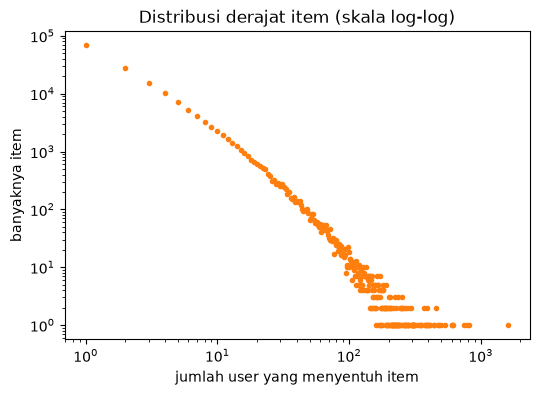

In [38]:
nilai, frek = np.unique(deg_item, return_counts=True)
plt.figure(figsize=(6, 4))
plt.loglog(nilai, frek, "o", ms=3, color="tab:orange")
plt.xlabel("jumlah user yang menyentuh item")
plt.ylabel("banyaknya item")
plt.title("Distribusi derajat item (skala log-log)")
plt.show()

In [39]:
import time

batas_atas_item = int((deg_user * (deg_user - 1) / 2).sum())
maks_sisi_item = n_item * (n_item - 1) // 2
punya_tetangga_item = np.asarray(BT @ (deg_user >= 2).astype(float)).ravel() > 0

t0 = time.perf_counter()
P_item = BT @ B                                            # item x item: jumlah user bersama
P_item = (P_item - sp.diags(P_item.diagonal())).tocsr()    # buang diagonal (item dengan dirinya sendiri)
P_item.eliminate_zeros()
waktu_item = time.perf_counter() - t0
sisi_item = P_item.nnz // 2

print(f"Simpul proyeksi item          : {n_item:,}")
print(f"Sisi maksimum n(n-1)/2        : {maks_sisi_item:,}")
print(f"Batas atas sisi Σ C(d_user,2) : {batas_atas_item:,}")
print(f"Sisi eksak                    : {sisi_item:,}")
print(f"Densitas proyeksi             : {sisi_item / maks_sisi_item:.4%}")
print(f"Rata-rata tetangga per item   : {P_item.nnz / n_item:.1f}")
print(f"Item yang punya tetangga      : {punya_tetangga_item.mean():.1%}")
print(f"Waktu hitung                  : {waktu_item:.2f} detik")
print(f"Memori proyeksi               : {(P_item.data.nbytes + P_item.indices.nbytes + P_item.indptr.nbytes) / 2**20:.1f} MB")

Simpul proyeksi item          : 167,663
Sisi maksimum n(n-1)/2        : 14,055,356,953
Batas atas sisi Σ C(d_user,2) : 1,879,238
Sisi eksak                    : 1,674,898
Densitas proyeksi             : 0.0119%
Rata-rata tetangga per item   : 20.0
Item yang punya tetangga      : 59.3%
Waktu hitung                  : 1.36 detik
Memori proyeksi               : 39.0 MB


In [40]:
calon_i = [i for i in np.flatnonzero((deg_item >= 3) & (deg_item <= 5))
           if (deg_user[BT[i].indices] >= 2).sum() >= 2 and deg_user[BT[i].indices].max() <= 6]
i0 = int(rng.choice(calon_i))
user_sampel = BT[i0].indices

G2 = nx.Graph()
for u in user_sampel:
    for i in B[u].indices:
        G2.add_edge(f"U{idx_user[u]}", f"I{idx_item[i]}")
item_nodes = [n for n in G2 if n.startswith("I")]
P_item_sampel = bipartite.weighted_projected_graph(G2, item_nodes)
print("Item pusat:", idx_item[i0], "| user:", len(user_sampel), "| item di sampel:", len(item_nodes))

Item pusat: 251945 | user: 5 | item di sampel: 4


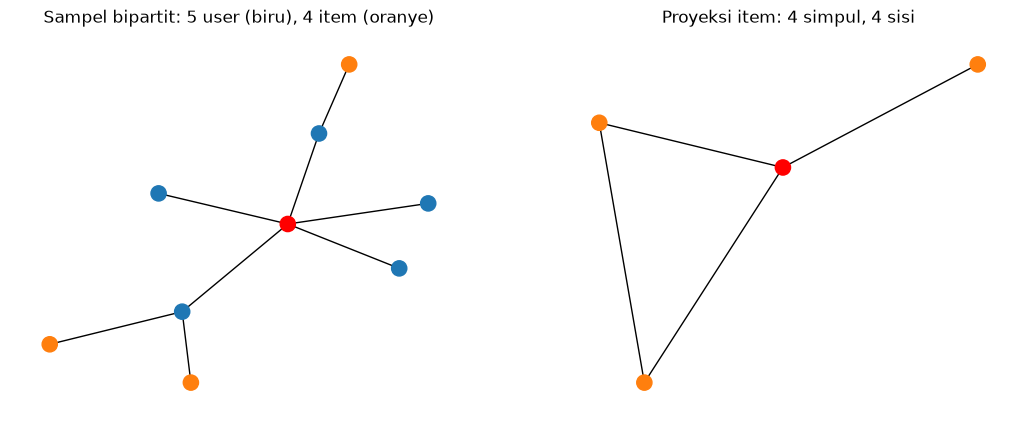

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
pusat_i = f"I{idx_item[i0]}"

pos = nx.spring_layout(G2, seed=1)
warna = ["red" if n == pusat_i else ("tab:orange" if n.startswith("I") else "tab:blue") for n in G2]
nx.draw(G2, pos, ax=ax[0], node_color=warna, node_size=120)
ax[0].set_title(f"Sampel bipartit: {len(user_sampel)} user (biru), {len(item_nodes)} item (oranye)")

pos2 = nx.spring_layout(P_item_sampel, seed=1)
warna2 = ["red" if n == pusat_i else "tab:orange" for n in P_item_sampel]
lebar = [P_item_sampel[a][b]["weight"] for a, b in P_item_sampel.edges()]
nx.draw(P_item_sampel, pos2, ax=ax[1], node_color=warna2, node_size=120, width=lebar)
ax[1].set_title(f"Proyeksi item: {P_item_sampel.number_of_nodes()} simpul, {P_item_sampel.number_of_edges()} sisi")
plt.show()

### Penjelasan No. 5 — VSM simpul Item
Matriks yang sama dibaca dari sisi item: setiap item adalah satu baris matriks **Bᵀ** (item × user), yaitu vektor
berdimensi **664.796** (jumlah user), sehingga shape-nya **(167.663, 664.796)**. Densitasnya sama dengan VSM user
(0,000869%) karena isinya adalah 969.116 interaksi yang sama. Namun karena jumlah item lebih sedikit, vektor item
lebih terisi: rata-rata 5,78 user per item (median 2, maksimum 1.621), dan hanya 41,3% item yang disentuh oleh 1 user.
Distribusi derajat item juga berpola *long-tail*, dengan ekor yang lebih panjang (item terpopuler disentuh 1.621 user).

Pada proyeksi Item–Item, dua item terhubung jika ada user yang menyentuh keduanya, sehingga setiap user dengan *d* item
membentuk klik berisi C(d,2) sisi. Karena 80,5% user hanya menyentuh 1 item, sebagian besar user tidak menyumbang sisi
sama sekali. Proyeksi item dapat dihitung secara eksak (Bᵀ·B): **1.674.898 sisi** (batas atas 1.879.238), densitas
0,0119%, rata-rata 20 tetangga per item, dan 59,3% item memiliki tetangga. Perhitungannya hanya **1,36 detik** dengan
memori **39 MB**. Plot networkx pada sampel memperlihatkan hal ini: dari 5 user yang menyentuh item pusat, 3 user hanya
memiliki item itu sehingga tidak menghasilkan sisi, sedangkan 2 user lainnya membentuk klik berisi 2 dan 3 item,
total 1 + 3 = 4 sisi.

## 2.1 No. 6 — Proyeksi mana yang lebih baik?

In [42]:
import gc

t0 = time.perf_counter()
P_user_full = B @ BT                                                  # user x user
P_user_full = (P_user_full - sp.diags(P_user_full.diagonal())).tocsr()
P_user_full.eliminate_zeros()
waktu_user = time.perf_counter() - t0

sisi_user = P_user_full.nnz // 2
memori_user = (P_user_full.data.nbytes + P_user_full.indices.nbytes + P_user_full.indptr.nbytes) / 2**20
print(f"Sisi eksak proyeksi user : {sisi_user:,}")
print(f"Densitas                 : {sisi_user / maks_sisi_user:.4%}")
print(f"Rata-rata tetangga/user  : {P_user_full.nnz / n_user:.1f}")
print(f"Waktu hitung             : {waktu_user:.2f} detik")
print(f"Memori                   : {memori_user:,.1f} MB")

del P_user_full      # hapus dari memori, karena no. 7 memakai proyeksi item
gc.collect()

Sisi eksak proyeksi user : 20,750,949
Densitas                 : 0.0094%
Rata-rata tetangga/user  : 62.4
Waktu hitung             : 8.73 detik
Memori                   : 477.5 MB


27158

In [43]:
# User yang hanya punya 1 item -> kembar jika ada user lain yang satu-satunya itemnya sama
u1 = np.flatnonzero(deg_user == 1)
item_milik_u1 = B[u1].indices
kembar_user = pd.Series(item_milik_u1).duplicated(keep=False).sum()

# Item yang hanya disentuh 1 user -> kembar jika ada item lain yang satu-satunya user-nya sama
i1 = np.flatnonzero(deg_item == 1)
user_milik_i1 = BT[i1].indices
kembar_item = pd.Series(user_milik_i1).duplicated(keep=False).sum()

print(f"User dengan vektor kembar : {kembar_user:,} ({kembar_user / n_user:.1%} dari semua user)")
print(f"Item dengan vektor kembar : {kembar_item:,} ({kembar_item / n_item:.1%} dari semua item)")

User dengan vektor kembar : 472,995 (71.1% dari semua user)
Item dengan vektor kembar : 11,934 (7.1% dari semua item)


In [44]:
memori_item = (P_item.data.nbytes + P_item.indices.nbytes + P_item.indptr.nbytes) / 2**20
baris = [
    ("Simpul proyeksi",           n_user, n_item, "{:,.0f}"),
    ("Dimensi vektor",            n_item, n_user, "{:,.0f}"),
    ("Batas atas sisi Σ C(d,2)",  batas_atas_user, batas_atas_item, "{:,.0f}"),
    ("Sisi eksak",                sisi_user, sisi_item, "{:,.0f}"),
    ("Densitas proyeksi",         sisi_user / maks_sisi_user, sisi_item / maks_sisi_item, "{:.4%}"),
    ("Rata-rata tetangga",        2 * sisi_user / n_user, 2 * sisi_item / n_item, "{:.1f}"),
    ("Simpul punya tetangga",     punya_tetangga.mean(), punya_tetangga_item.mean(), "{:.1%}"),
    ("Vektor hanya 1 interaksi",  (deg_user == 1).mean(), (deg_item == 1).mean(), "{:.1%}"),
    ("Vektor kembar",             kembar_user / n_user, kembar_item / n_item, "{:.1%}"),
    ("Waktu hitung (detik)",      waktu_user, waktu_item, "{:.2f}"),
    ("Memori proyeksi (MB)",      memori_user, memori_item, "{:,.1f}"),
]
banding = pd.DataFrame([(nama, f.format(a), f.format(b)) for nama, a, b, f in baris],
                       columns=["Ukuran", "Proyeksi User", "Proyeksi Item"]).set_index("Ukuran")
banding

,Proyeksi User,Proyeksi Item
Ukuran,,
Simpul proyeksi,"664,796","167,663"
Dimensi vektor,"167,663","664,796"
"Batas atas sisi Σ C(d,2)","21,280,204","1,879,238"
Sisi eksak,"20,750,949","1,674,898"
Densitas proyeksi,0.0094%,0.0119%
Rata-rata tetangga,62.4,20.0
Simpul punya tetangga,93.2%,59.3%
Vektor hanya 1 interaksi,80.5%,41.3%
Vektor kembar,71.1%,7.1%


### Penjelasan No. 6 — Proyeksi mana yang lebih baik?
**Proyeksi Item lebih baik, baik dari sisi efisiensi maupun efektivitas.**

**Efisien.** Proyeksi item hanya memiliki 167.663 simpul dan 1.674.898 sisi, sedangkan proyeksi user memiliki
664.796 simpul dan 20.750.949 sisi (12,4 kali lebih banyak). Proyeksi item dihitung dalam 1,36 detik dengan memori
39 MB, sedangkan proyeksi user membutuhkan 8,73 detik dan 477,5 MB. Penyebabnya struktural: item yang disentuh *d* user
membentuk klik berisi C(d,2) sisi di proyeksi user (item terpopuler dengan 1.621 user sendirian menyumbang ±1,3 juta
sisi), sedangkan 80,5% user hanya menyentuh 1 item sehingga tidak menyumbang sisi apa pun ke proyeksi item.

**Efektif.** Proyeksi user tampak lebih terhubung (93,2% simpul memiliki tetangga, rata-rata 62,4 tetangga), tetapi
hubungan itu sebagian besar tidak bermakna. Sebanyak 80,5% vektor user hanya berisi 1 interaksi, dan **71,1% user
memiliki vektor kembar**, yaitu vektor yang identik dengan user lain karena satu-satunya item mereka sama. Pasangan
seperti ini selalu bernilai cosine = 1, sehingga similarity tidak dapat membedakan mereka. Pada proyeksi item, hanya
41,3% vektor yang berisi 1 interaksi dan hanya **7,1%** yang kembar, sehingga nilai similarity antaritem lebih stabil
dan informatif. Keterbatasannya, 40,7% item tidak memiliki tetangga sehingga tidak dapat dicarikan item serupa.

Kesimpulan ini sejalan dengan praktik *item-based collaborative filtering* di e-commerce: katalog item lebih kecil dan
lebih stabil daripada populasi pengunjung, yang sebagian besar hanya berkunjung sekali.

## 2.1 No. 7 — Similarity pada graf terproyeksi

In [45]:
x = int(np.argmax(deg_item))                  # posisi item terpopuler
ITEM_ACUAN = int(idx_item[x])
d_x = deg_item[x]

baris_x = P_item[x]                           # tetangga item acuan di proyeksi item
tetangga = baris_x.indices
irisan = baris_x.data
d_y = deg_item[tetangga]

sim = pd.DataFrame({
    "item_mirip": idx_item[tetangga].to_numpy(),
    "irisan": irisan.astype(int),
    "deg_x": int(d_x),
    "deg_y": d_y.astype(int),
    "cosine": irisan / np.sqrt(d_x * d_y),
    "jaccard": irisan / (d_x + d_y - irisan),
}).sort_values(["cosine", "item_mirip"], ascending=[False, True], ignore_index=True)

print(f"Item acuan: {ITEM_ACUAN} (disentuh {d_x:,.0f} user) | jumlah tetangga: {len(tetangga):,}")
TOP5_PY = sim.head(5)
TOP5_PY

Item acuan: 5411 (disentuh 1,621 user) | jumlah tetangga: 481


,item_mirip,irisan,deg_x,deg_y,cosine,jaccard
0,33030,66,1621,111,0.155593,0.039616
1,33956,21,1621,33,0.090797,0.012860
2,358234,23,1621,44,0.086121,0.014007
3,37807,15,1621,26,0.073066,0.009191
4,459936,31,1621,127,0.068323,0.018055


### 7(a) — Cypher untuk 5 record dengan similarity tertinggi

In [46]:
Q_TOP5 = """
MATCH (x:Item {itemId: $acuan})<-[rx:VIEWED|ADDED_TO_CART|BOUGHT]-(vx:Visitor)
WHERE rx.fold = 'P1'
WITH x, count(DISTINCT vx) AS deg_x
MATCH (x)<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(y:Item)
WHERE r1.fold = 'P1' AND r2.fold = 'P1' AND y <> x
WITH x, deg_x, y, count(DISTINCT v) AS irisan
MATCH (y)<-[ry:VIEWED|ADDED_TO_CART|BOUGHT]-(vy:Visitor)
WHERE ry.fold = 'P1'
WITH y, deg_x, irisan, count(DISTINCT vy) AS deg_y
RETURN y.itemId AS item_mirip, irisan, deg_x, deg_y,
       toFloat(irisan) / sqrt(toFloat(deg_x) * deg_y) AS cosine,
       toFloat(irisan) / (deg_x + deg_y - irisan) AS jaccard
ORDER BY cosine DESC, item_mirip ASC
LIMIT 5
"""
t0 = time.perf_counter()
TOP5_CYPHER = cypher(Q_TOP5, acuan=ITEM_ACUAN)
print(f"Waktu query: {time.perf_counter() - t0:.2f} detik")
TOP5_CYPHER

Waktu query: 13.23 detik


,item_mirip,irisan,deg_x,deg_y,cosine,jaccard
0,33030,66,1621,111,0.155593,0.039616
1,33956,21,1621,33,0.090797,0.012860
2,358234,23,1621,44,0.086121,0.014007
3,37807,15,1621,26,0.073066,0.009191
4,459936,31,1621,127,0.068323,0.018055


In [47]:
sama = (TOP5_CYPHER["item_mirip"].tolist() == TOP5_PY["item_mirip"].tolist()
        and np.allclose(TOP5_CYPHER["cosine"], TOP5_PY["cosine"]))
print("Hasil Cypher sama dengan Python:", sama)

Hasil Cypher sama dengan Python: True


### 7(b) — Menulis nilai similarity ke graf

In [48]:
Q_TULIS = """
UNWIND $rows AS row
MATCH (x:Item {itemId: $acuan})
MATCH (y:Item {itemId: row.item_mirip})
MERGE (x)-[s:SIMILAR]->(y)
SET s.cosine = row.cosine, s.jaccard = row.jaccard, s.irisan = row.irisan
"""
Q_HITUNG = "MATCH ()-[s:SIMILAR]->() RETURN count(s) AS jumlah_SIMILAR"
Q_BACA = """
MATCH (x:Item {itemId: $acuan})-[s:SIMILAR]->(y:Item)
RETURN x.itemId AS acuan, y.itemId AS item_mirip, s.irisan AS irisan, s.cosine AS cosine, s.jaccard AS jaccard
ORDER BY cosine DESC, item_mirip ASC
"""

print("SEBELUM menulis:"); display(cypher(Q_HITUNG))
rows = TOP5_CYPHER[["item_mirip", "irisan", "cosine", "jaccard"]].to_dict(orient="records")
cypher(Q_TULIS, write=True, acuan=ITEM_ACUAN, rows=rows)
print("SESUDAH menulis:"); display(cypher(Q_HITUNG))
print("Hasil query relasi SIMILAR:")
cypher(Q_BACA, acuan=ITEM_ACUAN)

SEBELUM menulis:


Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `SIMILAR` does not exist in database `neo4j`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=13, offset=12>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 12, 'line': 1, 'column': 13}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: 'MATCH ()-[s:SIMILAR]->() RETURN count(s) AS jumlah_SIMILAR'


,jumlah_SIMILAR
0,0


SESUDAH menulis:


,jumlah_SIMILAR
0,5


Hasil query relasi SIMILAR:


,acuan,item_mirip,irisan,cosine,jaccard
0,5411,33030,66,0.155593,0.039616
1,5411,33956,21,0.090797,0.012860
2,5411,358234,23,0.086121,0.014007
3,5411,37807,15,0.073066,0.009191
4,5411,459936,31,0.068323,0.018055


## 2.1 No. 8 — Graf sebelum dan sesudah perhitungan similarity

In [49]:
TOP5_ID = TOP5_CYPHER["item_mirip"].tolist()

Q_SEBELUM_RINGKAS = """
MATCH p = (x:Item {itemId: $acuan})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(y:Item)
WHERE y.itemId IN $top5 AND r1.fold = 'P1' AND r2.fold = 'P1'
RETURN count(p) AS jumlah_jalur, count(DISTINCT v) AS visitor_perantara, count(DISTINCT y) AS item_terhubung
"""
Q_SESUDAH_RINGKAS = """
MATCH p = (x:Item {itemId: $acuan})-[s:SIMILAR]->(y:Item)
RETURN count(p) AS jumlah_jalur, count(DISTINCT y) AS item_terhubung,
       min(s.cosine) AS cosine_min, max(s.cosine) AS cosine_max
"""
print("SEBELUM (Item <- Visitor -> Item):")
display(cypher(Q_SEBELUM_RINGKAS, acuan=ITEM_ACUAN, top5=TOP5_ID))
print("SESUDAH (Item -[:SIMILAR]-> Item):")
display(cypher(Q_SESUDAH_RINGKAS, acuan=ITEM_ACUAN))

SEBELUM (Item <- Visitor -> Item):


,jumlah_jalur,visitor_perantara,item_terhubung
0,319,127,5


SESUDAH (Item -[:SIMILAR]-> Item):


,jumlah_jalur,item_terhubung,cosine_min,cosine_max
0,5,5,0.068323,0.155593


### Cypher dan hasil graf di Neo4j

**Sebelum similarity** — item acuan dan 5 item mirip hanya terhubung lewat visitor:
```cypher
MATCH p = (x:Item {itemId: 5411})<-[r1:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)-[r2:VIEWED|ADDED_TO_CART|BOUGHT]->(y:Item)
WHERE y.itemId IN [33030, 33956, 358234, 37807, 459936]
  AND r1.fold = 'P1' AND r2.fold = 'P1'
RETURN p LIMIT 300
```
![Graf sebelum similarity](gambar/sebelum.png)

**Sesudah similarity** — relasi langsung `SIMILAR` dengan nilai cosine:
```cypher
MATCH p = (x:Item {itemId: 5411})-[:SIMILAR]->(y:Item)
RETURN p
```
![Graf sesudah similarity](gambar/sesudah.png)

### Penjelasan No. 8 — Sebelum dan sesudah perhitungan similarity
**Sebelum** perhitungan similarity, item acuan 5411 dan kelima item mirip tidak memiliki hubungan langsung.
Mereka hanya terhubung secara tidak langsung melalui pola dua langkah Item ← Visitor → Item: terdapat
**[jumlah_jalur] jalur** yang melewati **[visitor_perantara] visitor** perantara. Di Neo4j, query SEBELUM
(dibatasi LIMIT 300 jalur) menampilkan 121 simpul (6 Item dan 115 Visitor) dengan 345 relasi interaksi.
Untuk mengetahui kemiripan antaritem, relasi-relasi ini harus ditelusuri dan dihitung ulang setiap kali dibutuhkan;
query 7(a) membutuhkan 13,23 detik.

**Sesudah** perhitungan similarity, nilai kemiripan disimpan sebagai **5 relasi langsung**
`(:Item)-[:SIMILAR]->(:Item)` dengan properti `cosine` (0,0683–0,1556), `jaccard`, dan `irisan`. Jumlah relasi
di database bertambah dari 1.511.339 menjadi 1.511.344. Item serupa kini cukup dibaca dalam satu langkah tanpa
menelusuri visitor, sehingga relasi SIMILAR dapat langsung dipakai untuk rekomendasi "item serupa".

# 2.2 Analytics
## No. 1 — Memilih user secara acak

In [51]:
pasangan_P2 = cypher("""
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.fold = 'P2'
RETURN v.visitorId AS visitorid, i.itemId AS itemid, count(r) AS n_interaksi
""")
print("Pasangan unik (visitor, item) di P2:", len(pasangan_P2))

Pasangan unik (visitor, item) di P2: 220687


In [52]:
item_P1_user = pasangan_P1.groupby("visitorid")["itemid"].apply(set)
item_P2_user = pasangan_P2.groupby("visitorid")["itemid"].apply(set)
katalog_P1 = set(idx_item)

# Ground truth: item BARU di P2 (belum disentuh di P1) yang ada di katalog P1
gt = {}
for u, item_p2 in item_P2_user.items():
    if u in item_P1_user.index:
        baru = (item_p2 - item_P1_user[u]) & katalog_P1
        if baru:
            gt[u] = baru

kandidat = sorted(u for u in gt if len(item_P1_user[u]) >= 2)
print(f"User aktif di P1 & P2 yang punya item baru : {len(gt):,}")
print(f"Kandidat (minimal 2 item di P1)            : {len(kandidat):,}")

rng_22 = np.random.default_rng(SEED)
USER = int(rng_22.choice(kandidat))
print(f"\nSEED = {SEED} -> user terpilih: {USER}")
print("Item user di P1   :", sorted(item_P1_user[USER]))
print("Ground truth (P2) :", sorted(gt[USER]))

User aktif di P1 & P2 yang punya item baru : 7,805
Kandidat (minimal 2 item di P1)            : 3,384

SEED = 23031554130 -> user terpilih: 329592
Item user di P1   : [156489, 207708, 211561]
Ground truth (P2) : [222285, 307755]


## No. 1(a) — Skrip Python KNN

In [53]:
K = 5
u = int(idx_user.get_loc(USER))                     # posisi baris user di matriks B
bu = B[u]                                           # vektor user (1 x jumlah item)

bersama = np.asarray((B @ bu.T).todense()).ravel()  # jumlah item bersama dengan setiap user
norma = np.sqrt(deg_user)                           # panjang vektor biner = akar jumlah item
sim = bersama / (norma * norma[u])                  # cosine dengan SEMUA user sekaligus
sim[u] = -1                                         # jangan pilih diri sendiri
sim[deg_user - bersama <= 0] = -1                   # tetangga tanpa item baru tidak bisa memberi rekomendasi

urut = np.lexsort((idx_user.to_numpy(), -sim))[:K]  # cosine terbesar; jika seri -> visitorId terkecil
tetangga = pd.DataFrame({
    "visitorid": idx_user[urut].to_numpy(),
    "cosine": sim[urut],
    "item_bersama": bersama[urut].astype(int),
    "jumlah_item": deg_user[urut].astype(int),
})
tetangga

,visitorid,cosine,item_bersama,jumlah_item
0,98265,0.408248,1,2
1,220242,0.408248,1,2
2,605838,0.408248,1,2
3,655399,0.408248,1,2
4,736363,0.408248,1,2


In [54]:
n_seri = int(np.isclose(sim, sim[urut[0]]).sum())
print(f"Cosine tertinggi = {sim[urut[0]]:.6f}, dimiliki oleh {n_seri:,} user "
      f"(dipilih {K} dengan visitorId terkecil)")

Cosine tertinggi = 0.408248, dimiliki oleh 10 user (dipilih 5 dengan visitorId terkecil)


## No. 1(b) — 3 item yang diiklankan (k = 5)

In [55]:
TOP_N = 5
skor = np.asarray(B[urut].T @ sim[urut]).ravel()    # skor item j = jumlah cosine tetangga yang menyentuh j
skor[bu.indices] = 0                                 # buang item yang sudah disentuh user
kand = np.flatnonzero(skor > 0)
kand = kand[np.lexsort((idx_item.to_numpy()[kand], -deg_item[kand], -skor[kand]))]

rek = list(kand[:TOP_N])
sumber = ["KNN"] * len(rek)
sudah = set(bu.indices)
for j in np.argsort(-deg_item, kind="stable"):      # pengisi jika kandidat KNN kurang dari 5
    if len(rek) >= TOP_N:
        break
    if j not in sudah and j not in rek:
        rek.append(j)
        sumber.append("populer (pengisi)")

tabel_rek = pd.DataFrame({
    "peringkat": range(1, len(rek) + 1),
    "itemid": idx_item[rek].to_numpy(),
    "skor_knn": skor[rek],
    "popularitas_P1": deg_item[rek].astype(int),
    "sumber": sumber,
})
REKOMENDASI = tabel_rek["itemid"].tolist()
IKLAN = REKOMENDASI[:3]
display(tabel_rek)
print("3 item yang diiklankan:", IKLAN)

,peringkat,itemid,skor_knn,popularitas_P1,sumber
0,1,264706,0.408248,53,KNN
1,2,106027,0.408248,26,KNN
2,3,244582,0.408248,9,KNN
3,4,207129,0.408248,8,KNN
4,5,55550,0.408248,1,KNN


3 item yang diiklankan: [264706, 106027, 244582]


## No. 2 — Evaluasi Hit@5 dan NDCG@5
Ground truth (GT) = item baru yang disentuh user pada fold testing P2.

- **Hit@5** = 1 jika minimal satu item di top-5 rekomendasi ada di GT, selain itu 0.
- **DCG@5** = Σᵢ relᵢ / log₂(i+1), dengan relᵢ = 1 jika item di peringkat i ada di GT.
- **IDCG@5** = DCG terbaik yang mungkin, yaitu jika semua item GT berada di peringkat teratas:
  Σ 1/log₂(i+1) untuk i = 1 sampai min(|GT|, 5).
- **NDCG@5** = DCG@5 / IDCG@5, bernilai 0–1. Semakin tinggi posisi item yang benar, semakin besar nilainya.

In [56]:
GT = gt[USER]

def hit_at_k(rek, gt, k=5):
    return int(len(set(rek[:k]) & gt) > 0)

def ndcg_at_k(rek, gt, k=5):
    dcg = sum(1 / np.log2(i + 2) for i, item in enumerate(rek[:k]) if item in gt)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(gt), k)))
    return dcg / idcg

rinci = pd.DataFrame({"peringkat i": range(1, 6), "itemid": REKOMENDASI[:5]})
rinci["rel_i"] = [int(it in GT) for it in rinci["itemid"]]
rinci["1/log2(i+1)"] = 1 / np.log2(rinci["peringkat i"] + 1)
rinci["kontribusi DCG"] = rinci["rel_i"] * rinci["1/log2(i+1)"]
display(rinci)

IDCG = sum(1 / np.log2(i + 2) for i in range(min(len(GT), 5)))
HIT5 = hit_at_k(REKOMENDASI, GT)
NDCG5 = ndcg_at_k(REKOMENDASI, GT)
print(f"Ground truth : {sorted(GT)}")
print(f"DCG@5        : {rinci['kontribusi DCG'].sum():.4f}")
print(f"IDCG@5       : {IDCG:.4f}")
print(f"Hit@5        : {HIT5}")
print(f"NDCG@5       : {NDCG5:.4f}")

,peringkat i,itemid,rel_i,1/log2(i+1),kontribusi DCG
0,1,264706,0,1.000000,0.0
1,2,106027,0,0.630930,0.0
2,3,244582,0,0.500000,0.0
3,4,207129,0,0.430677,0.0
4,5,55550,0,0.386853,0.0


Ground truth : [222285, 307755]
DCG@5        : 0.0000
IDCG@5       : 1.6309
Hit@5        : 0
NDCG@5       : 0.0000


In [57]:
# 1) Apakah 5 user lain yang seri (tidak terpilih) punya item yang ada di GT?
seri = np.flatnonzero(np.isclose(sim, sim[urut[0]]))
for n in seri:
    item_baru = set(idx_item[B[n].indices]) - item_P1_user[USER]
    status = "dipilih" if n in urut else "tidak dipilih"
    print(f"Tetangga {idx_user[n]} ({status}): item baru {sorted(item_baru)} | ada di GT? {bool(item_baru & GT)}")

# 2) Apakah item GT pernah dilihat bersama item milik user di P1 (cek di proyeksi item)?
print()
for g in sorted(GT):
    jg = idx_item.get_loc(g)
    co = sum(P_item[j, jg] for j in bu.indices)
    print(f"Item GT {g}: popularitas P1 = {deg_item[jg]:.0f} user | dilihat bersama item user = {co:.0f} kali")

Tetangga 98265 (dipilih): item baru [244582] | ada di GT? False
Tetangga 220242 (dipilih): item baru [207129] | ada di GT? False
Tetangga 605838 (dipilih): item baru [264706] | ada di GT? False
Tetangga 655399 (dipilih): item baru [106027] | ada di GT? False
Tetangga 736363 (dipilih): item baru [55550] | ada di GT? False
Tetangga 993976 (tidak dipilih): item baru [321077] | ada di GT? False
Tetangga 1091843 (tidak dipilih): item baru [18778] | ada di GT? False
Tetangga 1167879 (tidak dipilih): item baru [143990] | ada di GT? False
Tetangga 1186201 (tidak dipilih): item baru [363601] | ada di GT? False
Tetangga 1216731 (tidak dipilih): item baru [134524] | ada di GT? False

Item GT 222285: popularitas P1 = 43 user | dilihat bersama item user = 0 kali
Item GT 307755: popularitas P1 = 19 user | dilihat bersama item user = 0 kali


In [58]:
id_user, id_item = idx_user.to_numpy(), idx_item.to_numpy()
populer = np.argsort(-deg_item, kind="stable")

def knn_untuk(u, k=K, top_n=TOP_N):
    """Langkah yang sama persis dengan Sel 3 dan Sel 5, dibungkus jadi fungsi."""
    bu = B[u]
    bersama = np.asarray((B @ bu.T).todense()).ravel()
    sim = bersama / (norma * norma[u])
    sim[u] = -1
    sim[deg_user - bersama <= 0] = -1
    batas = np.partition(sim, -k)[-k]                     # nilai cosine ke-k terbesar (lebih cepat)
    calon = np.flatnonzero(sim >= batas)
    urut = calon[np.lexsort((id_user[calon], -sim[calon]))][:k]
    skor = np.asarray(B[urut].T @ sim[urut]).ravel()
    skor[bu.indices] = 0
    kand = np.flatnonzero(skor > 0)
    kand = kand[np.lexsort((id_item[kand], -deg_item[kand], -skor[kand]))]
    rek, sudah = list(kand[:top_n]), set(bu.indices)
    for j in populer:
        if len(rek) >= top_n:
            break
        if j not in sudah and j not in rek:
            rek.append(j)
    return [int(id_item[j]) for j in rek]

def populer_untuk(u, top_n=TOP_N):
    sudah = set(B[u].indices)
    return [int(id_item[j]) for j in populer[:top_n + len(sudah)] if j not in sudah][:top_n]

assert knn_untuk(u) == REKOMENDASI, "Fungsi harus menghasilkan rekomendasi yang sama dengan Sel 5"

rng_eval = np.random.default_rng(SEED + 1)
sampel = rng_eval.choice(kandidat, size=1000, replace=False)
hasil = []
for usr in tqdm(sampel, desc="Evaluasi"):
    uu = int(idx_user.get_loc(int(usr)))
    rk, rp, g = knn_untuk(uu), populer_untuk(uu), gt[int(usr)]
    hasil.append({"Hit@5 KNN": hit_at_k(rk, g), "NDCG@5 KNN": ndcg_at_k(rk, g),
                  "Hit@5 Populer": hit_at_k(rp, g), "NDCG@5 Populer": ndcg_at_k(rp, g)})
pd.DataFrame(hasil).mean().round(4)

Evaluasi: 100%|██████████| 1000/1000 [01:55<00:00,  8.63it/s]


Hit@5 KNN         0.0300
NDCG@5 KNN        0.0138
Hit@5 Populer     0.0060
NDCG@5 Populer    0.0031
dtype: float64

### Penjelasan 2.2 No. 1 — KNN dan item yang diiklankan
**Proses acak.** Kandidat adalah user yang (i) memiliki minimal 2 item di P1, agar vektornya tidak kembar dengan user
lain (lihat no. 6), dan (ii) menyentuh minimal satu item baru di P2 yang ada di katalog P1, agar rekomendasinya dapat
dievaluasi. Dari 7.805 user yang memiliki ground truth, 3.384 memenuhi syarat. Kandidat diurutkan menurut `visitorId`,
lalu satu user dipilih dengan `np.random.default_rng(SEED)` dengan SEED = NIM (23031554130), sehingga hasilnya selalu
sama: **user 329592**, yang memiliki 3 item di P1.

**KNN (1a).** Cosine similarity dihitung antara vektor user terpilih dan seluruh 664.796 vektor user dalam satu operasi
(B·bᵤ), tanpa membangun seluruh proyeksi user. User yang seluruh itemnya sudah dimiliki user terpilih dibuang karena
tidak dapat menyumbang item baru. Kelima tetangga terdekat (k = 5) memiliki cosine 0,408 = 1/√(3·2): masing-masing
memiliki 2 item dan berbagi 1 item dengan user terpilih. Terdapat 10 user dengan nilai seri ini, dan 5 dipilih
berdasarkan `visitorId` terkecil.

**Rekomendasi (1b).** Skor setiap item adalah jumlah cosine tetangga yang menyentuhnya. Item yang sudah disentuh user
dibuang, dan skor yang seri diurutkan berdasarkan popularitas di P1. **Tiga item yang diiklankan adalah 264706, 106027,
dan 244582.**

### Penjelasan 2.2 No. 2 — Hit@5 dan NDCG@5
Ground truth user 329592 di P2 adalah item 222285 dan 307755. Tidak ada satu pun dari top-5 rekomendasi yang termasuk
ground truth, sehingga **Hit@5 = 0** dan **NDCG@5 = 0** (DCG@5 = 0; IDCG@5 = 1 + 1/log₂3 = 1,6309).

Diagnosis menunjukkan hasil ini bersifat struktural, bukan kesalahan metode: (1) tidak satu pun dari 10 tetangga yang
seri memiliki item ground truth, sehingga memilih tetangga yang lain pun tidak akan menghasilkan hit; (2) kedua item
ground truth tidak pernah dilihat bersama item milik user di P1, sehingga tidak ada metode collaborative filtering
berbasis P1 yang dapat menemukannya.

Sebagai pembanding, evaluasi pada 1.000 kandidat acak (seed SEED+1) menghasilkan **Hit@5 = 0,030** dan
**NDCG@5 = 0,0138** untuk KNN, sedangkan baseline popularitas hanya mencapai Hit@5 = 0,006 dan NDCG@5 = 0,0031.
KNN sekitar **5 kali lebih baik** daripada baseline, meskipun nilai absolutnya rendah. Hal ini wajar untuk data
RetailRocket yang sangat jarang: sebagian besar user hanya memiliki sedikit interaksi, banyak tetangga bernilai seri,
dan item baru di P2 sering kali tidak terhubung dengan riwayat user di P1.